# 08 — Direction, prediction and verdict

Notebook 06 showed that the PM2.5–search relationship in Bangkok and Kraków survives removing the season. This notebook asks two further questions and then draws the project together.

1. **Direction.** Does past pollution help forecast future attention (Granger causality), and does the reverse placebo stay quiet?
2. **Prediction.** How much does PM2.5 improve an out-of-sample forecast of attention, beyond what the calendar alone gives?
3. **Verdict.** One conclusion per city, assembled from computed results.

Design choices that differ from the first iteration of this project:

| Earlier problem | What is done here |
|---|---|
| One series differenced, the other left in levels | Both series get the same transform: the seasonal fit is removed from each |
| Only PM2.5 → search tested | The reverse direction is tested as a placebo |
| 12 tests, no correction | Benjamini–Hochberg across all 24 tests |
| Lags built on a table with missing weeks | Lags built on a regular weekly index, so no lag reaches across a gap |
| Summary table typed in by hand | Every number in the verdict table is computed in this notebook |

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from aqs import awareness as A, causal as C, features as F, plots as P, stats as S
from aqs.config import PROCESSED

pd.set_option("display.precision", 3)
P.use_theme()
long = F.load_long()

## 1. Stationarity

Granger tests assume stationary series. The Augmented Dickey–Fuller test is run on PM2.5 and on the attention index, raw and with the season removed.

In [2]:
C.stationarity_table(long)

,city,series,version,adf_p,stationary
0,bangkok,PM2.5,raw,3.884e-03,True
1,bangkok,attention,raw,5.242e-02,False
2,bangkok,PM2.5,season removed,3.809e-18,True
3,bangkok,attention,season removed,1.057e-03,True
4,krakow,PM2.5,raw,1.627e-02,True
5,krakow,attention,raw,7.502e-02,False
6,krakow,PM2.5,season removed,8.294e-19,True
7,krakow,attention,season removed,2.870e-14,True
8,melbourne,PM2.5,raw,4.067e-05,True
9,melbourne,attention,raw,1.154e-09,True


**Reading it.** The raw attention index narrowly fails the test in Bangkok and Kraków. With the season removed, every series in every city is stationary. So the seasonal residuals are used for both series throughout: one transform, applied consistently.

## 2. Granger causality, both directions

The question for each direction: do the last *k* weeks of one series improve a forecast of the other, beyond that series' own last *k* weeks? The reverse direction is a placebo, since searching cannot change the air.

In [3]:
granger = C.granger_table(long)
granger

,city,direction,lags,weeks,F,p,p_fdr,significant
0,bangkok,PM2.5 → attention,1,148,0.026,0.871,0.950,False
1,bangkok,PM2.5 → attention,2,146,0.186,0.831,0.950,False
2,bangkok,PM2.5 → attention,3,144,0.526,0.665,0.950,False
3,bangkok,PM2.5 → attention,4,142,0.892,0.471,0.950,False
4,bangkok,attention → PM2.5 (placebo),1,148,0.333,0.565,0.950,False
5,bangkok,attention → PM2.5 (placebo),2,146,3.674,0.028,0.187,False
6,bangkok,attention → PM2.5 (placebo),3,144,3.576,0.016,0.187,False
7,bangkok,attention → PM2.5 (placebo),4,142,2.841,0.027,0.187,False
8,krakow,PM2.5 → attention,1,128,3.849,0.052,0.250,False
9,krakow,PM2.5 → attention,2,122,2.350,0.100,0.343,False


In [4]:
granger.pivot_table(index=["city", "direction"], columns="lags", values="p_fdr")

lags                                       1      2      3      4
city      direction                                              
bangkok   PM2.5 → attention            0.950  0.950  0.950  0.950
          attention → PM2.5 (placebo)  0.950  0.187  0.187  0.187
krakow    PM2.5 → attention            0.250  0.343  0.343  0.800
          attention → PM2.5 (placebo)  0.950  0.988  0.187  0.650
melbourne PM2.5 → attention            0.950  0.950  0.950  0.950
          attention → PM2.5 (placebo)  0.666  0.950  0.950  0.988

**Reading it.** No test is significant after correction, in either direction, in any city. Past pollution does not help forecast attention once attention's own past is known.

This is not evidence that pollution has no effect. Notebooks 06 and 07 showed the response happens *within the same week* and fades in a week or two. A Granger test only looks at earlier weeks, so a same-week response is invisible to it. At weekly resolution the test cannot establish which comes first.

It also explains an earlier result. The first iteration reported that PM2.5 Granger-causes search in Bangkok (p ≈ 0.008). In that version search weeks were labelled seven days early, which turns a same-week relationship into an apparent one-week lag. With the weeks aligned, that finding disappears.

What the direction of effect rests on instead: attention responds to pollution the calendar did not predict; the reverse path is physically impossible; and attention jumps in the week of a pollution spike. Establishing order in time would need daily data.

## 3. What does PM2.5 add to a forecast?

Two random forests predict the attention index: one from the calendar alone (month, as a sine/cosine pair), one from the calendar plus PM2.5 (this week, the previous four weeks, and a four-week average). Each week is predicted by a model trained only on earlier weeks, and R² is pooled over all held-out weeks.

Hyperparameters are fixed at 300 trees, depth 4, and at least 5 weeks per leaf: shallow trees and large leaves, because there are only around 100–140 weeks to learn from. The table reports depths 2, 4 and 6 to show the result does not depend on that choice.

In [5]:
skill, preds = C.forecast_skill(long)
skill.T

city,bangkok,krakow,melbourne
weeks,142,110,86
r2_calendar,0.284,0.42,-0.341
mae_calendar,0.386,0.457,0.574
r2_calendar_pm25,0.428,0.38,-0.326
mae_calendar_pm25,0.345,0.464,0.572
r2_gain_from_pm25,0.144,-0.041,0.015
r2_depth2,0.421,0.375,-0.323
r2_depth4,0.428,0.38,-0.326
r2_depth6,0.43,0.38,-0.326
importance_pm25,0.972,0.367,0.561


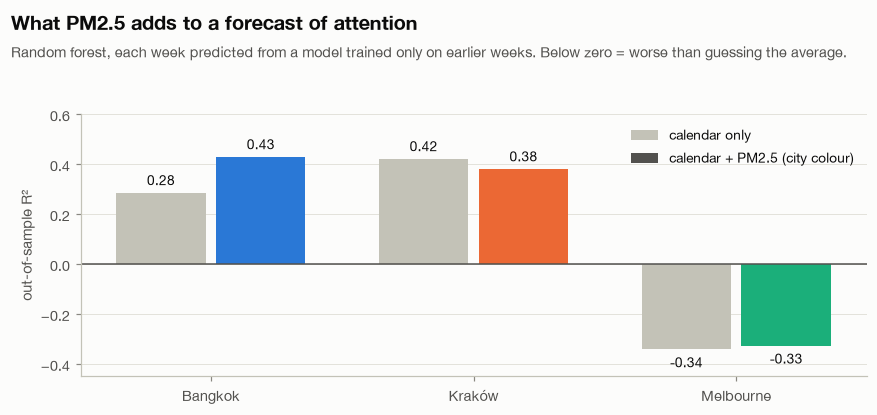

In [6]:
P.forecast_skill_plot(skill);

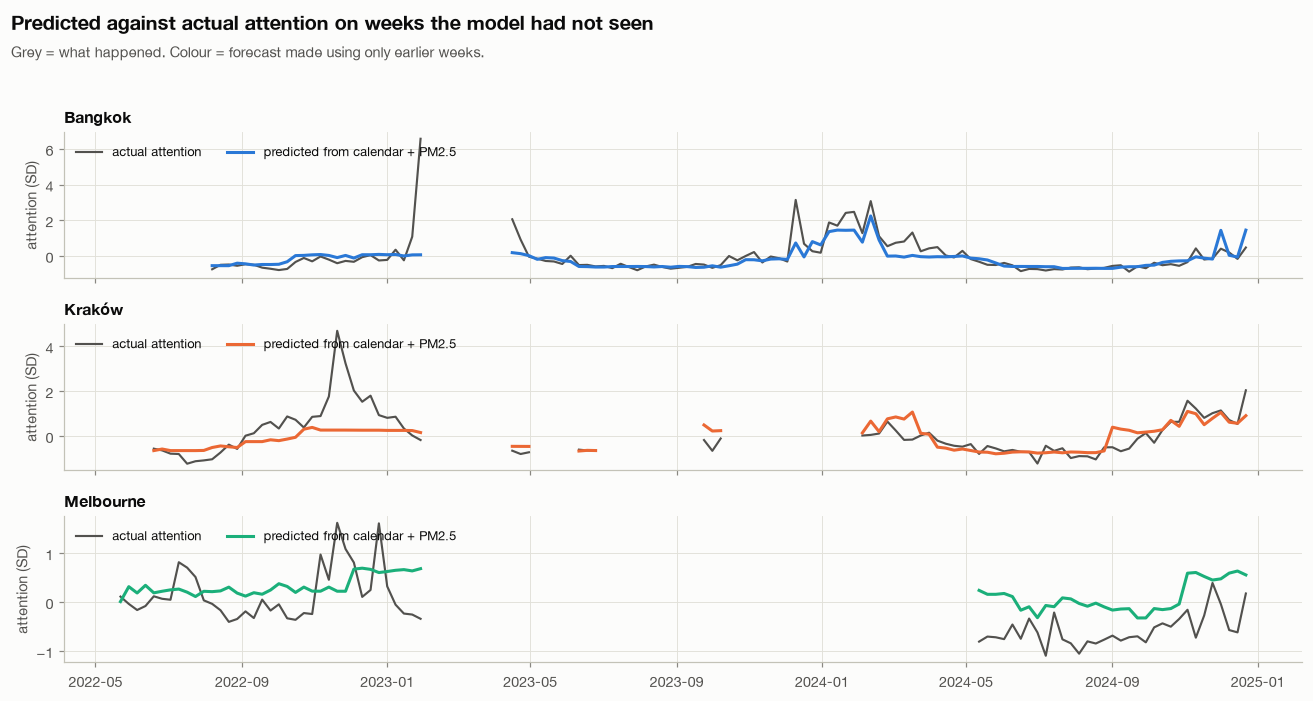

In [7]:
P.forecast_timeline(preds);

**Reading it.**

- **Bangkok.** Adding PM2.5 lifts out-of-sample R² from 0.28 to 0.43. Pollution carries information about attention that the calendar does not.
- **Kraków.** The calendar alone reaches 0.42, and adding PM2.5 does not improve on it. Kraków's attention is predictable from the time of year; knowing the actual pollution adds nothing to a forecast.
- **Melbourne.** Both models do worse than guessing the average.

Depth 2, 4 or 6 changes R² by less than 0.01 in every city.

Kraków's two results are consistent with each other. Attention there does respond to unexpected pollution (notebook 06), but that response is small next to the seasonal pattern (notebook 07, section 1), so it does not help a forecast.

## 4. Verdict table

In [8]:
corr = S.correlation_table(long)
card = A.scorecard(long)
verdict = C.verdicts(corr, granger, skill, card)
verdict.to_csv(PROCESSED / "verdicts.csv")
verdict.T

city,bangkok,krakow,melbourne
deseason_r,0.528,0.582,0.07
correlation_survives,True,True,False
granger_forward_min_p_fdr,0.95,0.25,0.95
granger_forward,False,False,False
granger_placebo_min_p_fdr,0.187,0.187,0.666
granger_placebo,False,False,False
r2_gain_from_pm25,0.144,-0.041,0.015
silent_share,0.02,0.089,0.5
habituation_per_week,0.07,-0.051,-0.051


## 5. Answer to the research question

**Does real-world PM2.5 show up in public search behaviour, at what lag, and does it hold across cities?**

| | Bangkok | Kraków | Melbourne |
|---|---|---|---|
| Correlation once the season is removed | 0.53, survives | 0.58, survives | 0.07, none |
| Lag | Same week | Same week | — |
| Past pollution forecasts attention (Granger) | No | No | No |
| PM2.5 improves an out-of-sample forecast | Yes (+0.14 R²) | No | No |
| Over a season | Attention builds | Attention wears out | — |
| Polluted weeks that go unnoticed | 2% | 9% | 50% |
| **Search as a proxy for awareness** | **Reliable** | **Real but mostly seasonal** | **Not informative** |

- **Bangkok.** Search tracks pollution closely, in the same week, including pollution the season did not predict. It is a usable real-time proxy for public awareness.
- **Kraków.** Search does respond to pollution, but most of what it shows is the heating season itself, and the response weakens as the season goes on. It is a proxy for "it is smog season", less so for "today is worse than usual".
- **Melbourne.** With PM2.5 almost always under the WHO guideline, there is nothing for search to track.

**The general point.** Whether search can stand in for public awareness depends on how severe and how variable the pollution is. This is the lesson of Google Flu Trends (Lazer et al., 2014) applied to air quality: a search signal that works in one setting should not be assumed to work in another, and a single correlation coefficient cannot tell the settings apart.

## Limitations

- **Three years of weekly data.** Episode and habituation estimates rest on five or six episodes and three seasons per city.
- **Gaps in the PM2.5 record.** OpenAQ has no data for February to mid-March 2023 in any city, which removes part of Bangkok's 2023 peak; Melbourne is missing about a year.
- **Weekly resolution.** The response is faster than a week, so the order of events cannot be established here.
- **Search is a relative index.** Google Trends reports interest relative to each series' own peak, so levels cannot be compared between cities, only patterns.
- **Kraków rests on two monitors**, and search for Kraków is measured for its whole province.
- **Three cities** illustrate the contrast; they do not prove a general rule.